# 03 — Analysis: baseline vs P1 ensemble vs P2 hybrid EMA+TTA

**Data are never filled manually.** Requires 15 JSON results: baseline (5), P1 (5), P2 (5). In Kaggle, attach the saved-version **Notebook Output** of `reproduce` and `02_advanced_ensemble_hybrid`. Also supports local ZIP files placed in `/kaggle/input`. Exports CSV and PNG to `/kaggle/working/outputs_03_advanced`.


In [1]:
from pathlib import Path
import json,zipfile,os
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from sklearn.metrics import f1_score
ROOTS=[Path('/kaggle/input'),Path('/kaggle/working'),Path.cwd()]
DEST=Path('/kaggle/working/outputs_03_advanced') if Path('/kaggle/working').exists() else Path.cwd()/'outputs_03_advanced'
DEST.mkdir(parents=True,exist_ok=True)
METHODS={'baseline':'resnet_tiny','P1_ensemble':'P1_ensemble','P2_hybrid_ema_tta':'P2_hybrid_ema_tta'}

def locate(name):
    # Search recursively across all mounted notebook outputs and current working.
    matches=[]
    for root in ROOTS:
        if root.exists():
            matches += [p for p in root.rglob(name) if p.is_file()]
    if matches:
        matches.sort(key=lambda p:(not str(p).startswith('/kaggle/input'),len(str(p))))
        return json.loads(matches[0].read_text()),str(matches[0])
    # Also read JSON stored inside Kaggle output archives (without extracting all files).
    for root in ROOTS:
        if root.exists():
            for zpath in root.rglob('*.zip'):
                try:
                    with zipfile.ZipFile(zpath) as z:
                        found=[n for n in z.namelist() if Path(n).name==name]
                        if found:return json.loads(z.read(found[0])),str(zpath)+'::'+found[0]
                except (zipfile.BadZipFile,OSError):pass
    return None,None

results={};missing=[]
print('=== KAGGLE OUTPUT DISCOVERY ===')
for m,prefix in METHODS.items():
    results[m]={}
    for fold in range(1,6):
        name=f'{prefix}_fold{fold}.json'
        r,where=locate(name)
        if r is None:missing.append(name)
        else:
            results[m][fold]=r
            print(m,fold,'<-',where)
    print(m,len(results[m]),'/5')
if missing:
    print('MISSING:',*missing,sep='\n - ')
    print('Attach Notebook Output from saved versions of reproduce and 02 advanced; check Output files.')
    raise FileNotFoundError(f'{len(missing)} JSON results missing. No synthetic data will be used.')
print('All 15 results loaded.')


=== KAGGLE OUTPUT DISCOVERY ===
baseline 1 <- /kaggle/input/datasets/salsabillafatika/esc50-result/results_baseline/results/resnet_tiny_fold1.json
baseline 2 <- /kaggle/input/datasets/salsabillafatika/esc50-result/results_baseline/results/resnet_tiny_fold2.json
baseline 3 <- /kaggle/input/datasets/salsabillafatika/esc50-result/results_baseline/results/resnet_tiny_fold3.json
baseline 4 <- /kaggle/input/datasets/salsabillafatika/esc50-result/results_baseline/results/resnet_tiny_fold4.json
baseline 5 <- /kaggle/input/datasets/salsabillafatika/esc50-result/results_baseline/results/resnet_tiny_fold5.json
baseline 5 /5
P1_ensemble 1 <- /kaggle/input/datasets/salsabillafatika/esc50-result/esc50_advanced_results/results/P1_ensemble_fold1.json
P1_ensemble 2 <- /kaggle/input/datasets/salsabillafatika/esc50-result/esc50_advanced_results/results/P1_ensemble_fold2.json
P1_ensemble 3 <- /kaggle/input/datasets/salsabillafatika/esc50-result/esc50_advanced_results/results/P1_ensemble_fold3.json
P1_ense

## 1. Per-fold metrics and summary

In [2]:
rows=[]
for method,folds in results.items():
    for fold,r in folds.items():
        rows.append({'method':method,'fold':fold,'accuracy':float(r['final_acc']),
                     'macro_f1':float(r.get('final_macro_f1',np.nan)),
                     'parameters':r.get('parameters',np.nan),'seconds':r.get('seconds',np.nan)})
df=pd.DataFrame(rows).sort_values(['method','fold'])
summary=df.groupby('method').agg(mean_accuracy=('accuracy','mean'),std_accuracy=('accuracy','std'),
                                  mean_f1=('macro_f1','mean'),std_f1=('macro_f1','std'),
                                  mean_parameters=('parameters','mean'),mean_seconds=('seconds','mean'))
print(df.to_string(index=False));display(summary)
df.to_csv(DEST/'fold_metrics.csv',index=False);summary.to_csv(DEST/'summary.csv')


           method  fold  accuracy  macro_f1  parameters     seconds
      P1_ensemble     1     91.50 91.259555   7112576.0 1802.320438
      P1_ensemble     2     88.50 88.255636   7112576.0 1779.781036
      P1_ensemble     3     89.25 89.167559   7112576.0 1780.218531
      P1_ensemble     4     91.50 91.190932   7112576.0 1781.337479
      P1_ensemble     5     85.00 84.001063   7112576.0 1780.086592
P2_hybrid_ema_tta     1     89.25 88.804441   2685778.0  444.860995
P2_hybrid_ema_tta     2     86.75 86.389069   2685778.0  444.963064
P2_hybrid_ema_tta     3     88.75 88.553441   2685778.0  445.429677
P2_hybrid_ema_tta     4     87.75 87.501343   2685778.0  445.442759
P2_hybrid_ema_tta     5     84.25 83.318621   2685778.0  445.262898
         baseline     1     84.75       NaN         NaN  413.734209
         baseline     2     87.00       NaN         NaN  415.109401
         baseline     3     89.50       NaN         NaN  415.161137
         baseline     4     88.25       NaN     

,mean_accuracy,std_accuracy,mean_f1,std_f1,mean_parameters,mean_seconds
method,,,,,,
P1_ensemble,89.15,2.678619,88.774949,2.967493,7112576.0,1784.748815
P2_hybrid_ema_tta,87.35,1.981161,86.913383,2.225354,2685778.0,445.191879
baseline,86.35,2.886390,NaN,NaN,NaN,414.834376


## 2. Paired t-test, official ESC-50 fold alignment

In [3]:
ref=df[df.method=='baseline'].set_index('fold').loc[range(1,6),'accuracy'].to_numpy()
tests=[]
for m in ['P1_ensemble','P2_hybrid_ema_tta']:
    comp=df[df.method==m].set_index('fold').loc[range(1,6),'accuracy'].to_numpy()
    stat,p=ttest_rel(comp,ref)
    tests.append({'method':m,'delta_percentage_points':float((comp-ref).mean()),'t_stat':float(stat),'p_value':float(p)})
tests=pd.DataFrame(tests);display(tests);tests.to_csv(DEST/'paired_tests.csv',index=False)
print('Caution: n=5; statistical power is low. Multiple comparisons are exploratory.')


,method,delta_percentage_points,t_stat,p_value
0,P1_ensemble,2.8,2.418832,0.072855
1,P2_hybrid_ema_tta,1.0,0.996890,0.375238


Caution: n=5; statistical power is low. Multiple comparisons are exploratory.


## 3. Accuracy by fold and aggregate

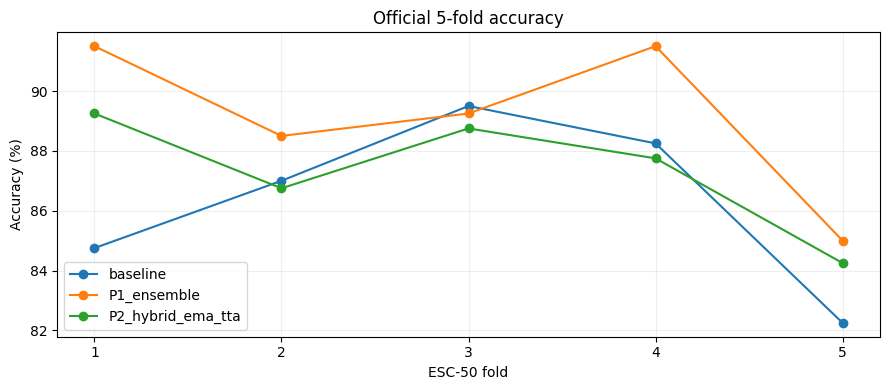

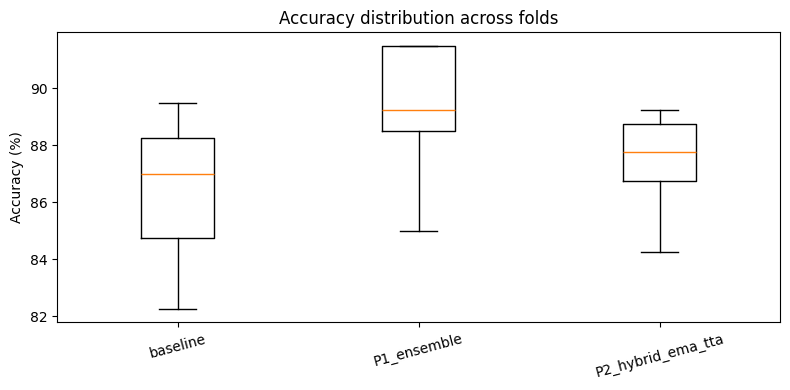

In [4]:
fig,ax=plt.subplots(figsize=(9,4))
for m in METHODS:
    d=df[df.method==m].sort_values('fold')
    ax.plot(d.fold,d.accuracy,marker='o',label=m)
ax.set(xlabel='ESC-50 fold',ylabel='Accuracy (%)',title='Official 5-fold accuracy');ax.set_xticks(range(1,6));ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(DEST/'accuracy_folds.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4))
ax.boxplot([df[df.method==m].accuracy for m in METHODS],tick_labels=list(METHODS))
ax.set(ylabel='Accuracy (%)',title='Accuracy distribution across folds');ax.tick_params(axis='x',rotation=15)
fig.tight_layout();fig.savefig(DEST/'accuracy_boxplot.png',dpi=160);plt.show()


## 4. Confusion matrix and class-wise F1 (if prediction records available)

baseline : no confusion matrix in source JSON (baseline may omit it)


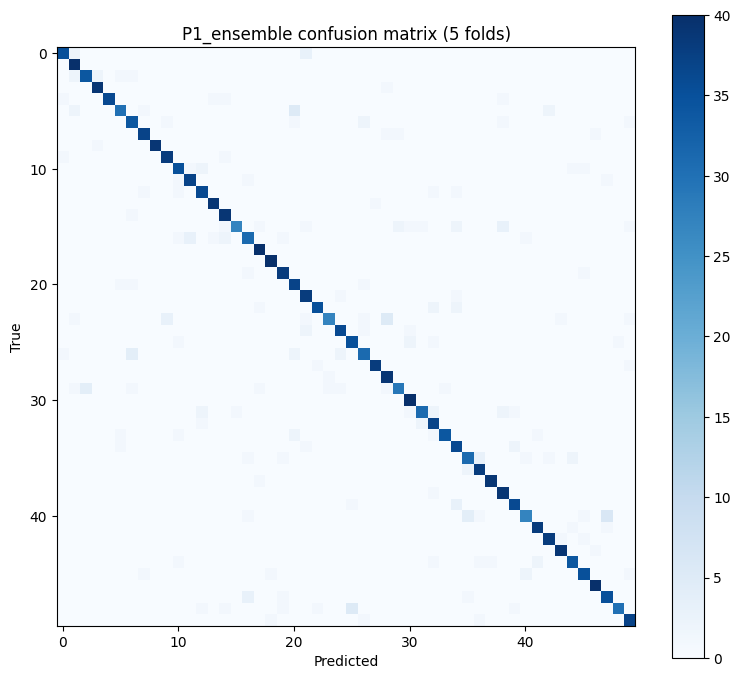

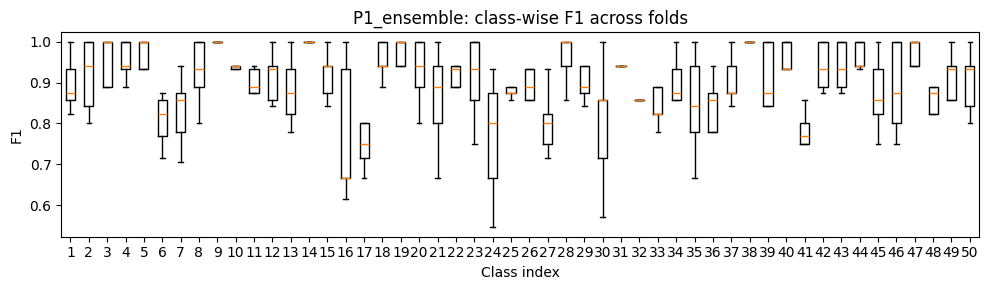

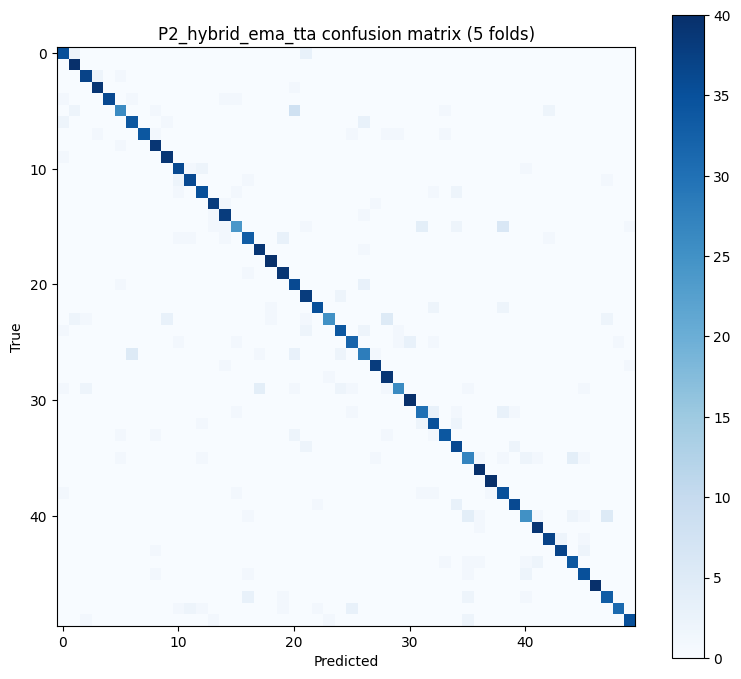

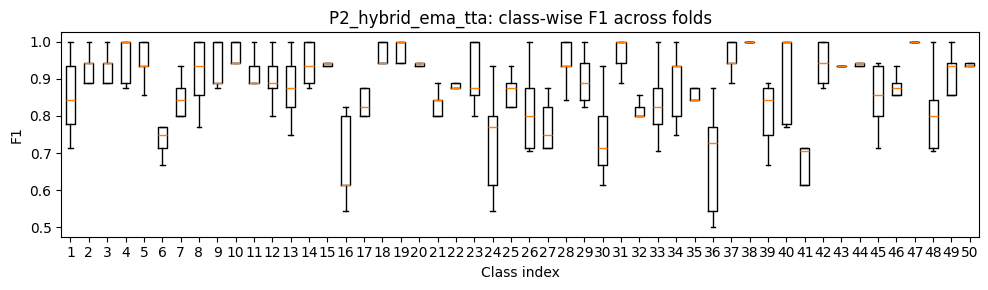

In [5]:
for m in METHODS:
    cms=[];f1_by_fold=[]
    for f,r in results[m].items():
        cm=np.asarray(r.get('confusion_matrix',[]))
        if cm.shape==(50,50):
            cms.append(cm)
            tp=np.diag(cm);prec=tp/np.maximum(cm.sum(axis=0),1);rec=tp/np.maximum(cm.sum(axis=1),1)
            f1_by_fold.append(2*prec*rec/np.maximum(prec+rec,1e-12))
    if not cms:
        print(m,': no confusion matrix in source JSON (baseline may omit it)');continue
    cm=np.sum(cms,axis=0)
    fig,ax=plt.subplots(figsize=(8,7));im=ax.imshow(cm,cmap='Blues');ax.set(title=f'{m} confusion matrix (5 folds)',xlabel='Predicted',ylabel='True')
    fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(DEST/f'{m}_confusion.png',dpi=150);plt.show()
    pd.DataFrame(cm).to_csv(DEST/f'{m}_confusion.csv',index=False)
    if f1_by_fold:
        fig,ax=plt.subplots(figsize=(10,3));ax.boxplot(np.asarray(f1_by_fold),showfliers=False)
        ax.set(xlabel='Class index',ylabel='F1',title=f'{m}: class-wise F1 across folds')
        fig.tight_layout();fig.savefig(DEST/f'{m}_class_f1.png',dpi=150);plt.show()


## 5. Learning curves (loss is TRAINING loss, not validation loss)

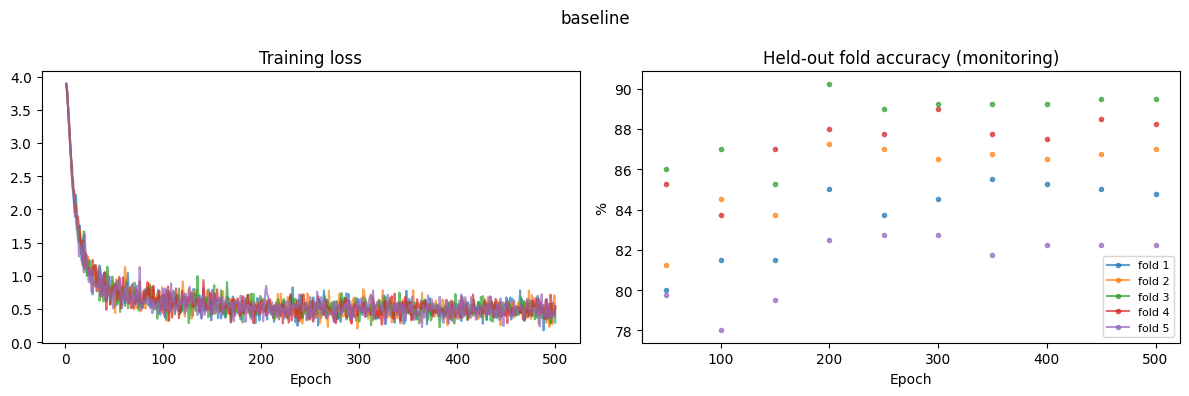

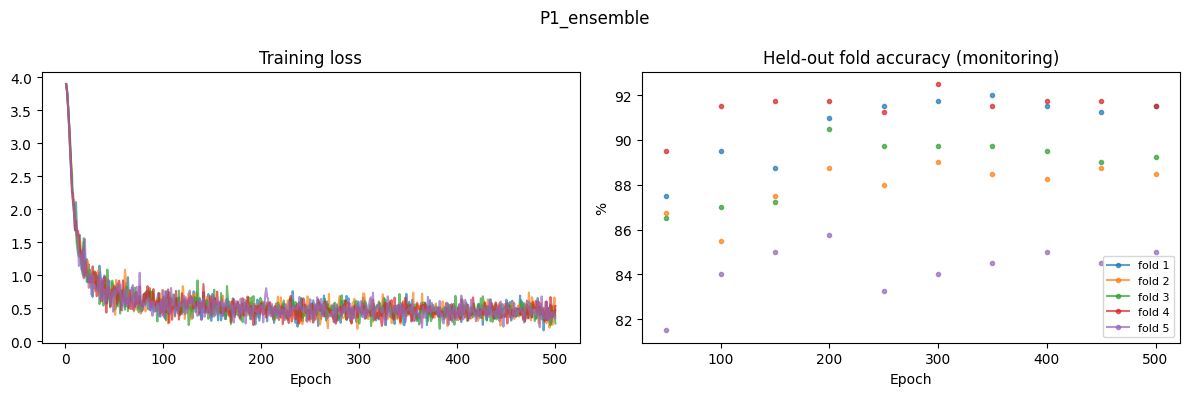

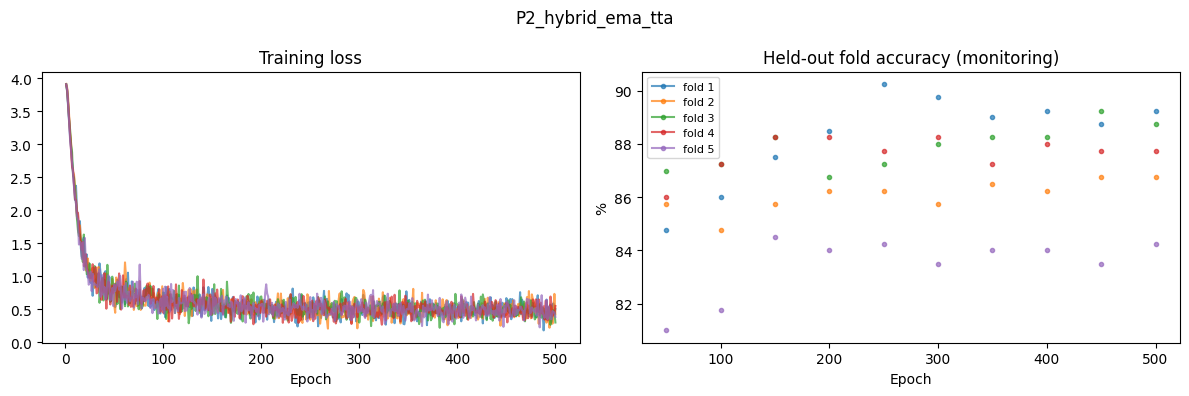

Analysis exports: /kaggle/working/outputs_03_advanced


In [6]:
for m in METHODS:
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    for f,r in results[m].items():
        hist=pd.DataFrame(r.get('history',[]))
        if hist.empty:continue
        if 'loss' in hist:axs[0].plot(hist.epoch,hist.loss,alpha=.7,label=f'fold {f}')
        key='test_acc' if 'test_acc' in hist else ('accuracy' if 'accuracy' in hist else None)
        if key:axs[1].plot(hist.epoch,hist[key],marker='.',alpha=.7,label=f'fold {f}')
    axs[0].set(title='Training loss',xlabel='Epoch');axs[1].set(title='Held-out fold accuracy (monitoring)',xlabel='Epoch',ylabel='%')
    axs[1].legend(fontsize=8);fig.suptitle(m);fig.tight_layout();fig.savefig(DEST/f'{m}_curves.png',dpi=160);plt.show()
print('Analysis exports:',DEST)
